In [6]:
!pip install "git+https://github.com/schmidt-neural-data-science/TDE-DP-GMM.git@main"


  Cloning https://github.com/schmidt-neural-data-science/TDE-DP-GMM.git (to revision main) to /tmp/pip-req-build-nswbi642
  Running command git clone --filter=blob:none --quiet https://github.com/schmidt-neural-data-science/TDE-DP-GMM.git /tmp/pip-req-build-nswbi642
  Resolved https://github.com/schmidt-neural-data-science/TDE-DP-GMM.git to commit 2c829dbed4df8dd7cfe73989d99644e2ea4d6a73
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.7/149.7 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 388.0/388.0 kB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 756.0/756.0 kB 30.0 MB/s eta 0:00:00
  Created wheel for nds-toolbox: filename=nds_toolbox-0.1.5-py3-none-any.whl size=30128 sha256=3dd68ea629cd845a31926e101e81c2ea24a78cc7b50ac509e7302fd9fa7cf0a2
  Stored in directory: /tmp/pip-ephem-wheel-cache-1e177hoj/wheels/8d/66/

In [2]:
import nds_toolbox
print(nds_toolbox.__version__)






0.1.5


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import pickle
import os

In [2]:

FIG_WIDTH = 7.5
MY_FONT_SIZE = 9

plt.rcParams.update({

    # --- Fonts ---
    "font.size": MY_FONT_SIZE,

    # --- Legend ---
    "legend.fontsize": MY_FONT_SIZE,
    "legend.frameon": False,

    # --- Titles ---
    "figure.titlesize": MY_FONT_SIZE,
    "axes.titleweight": "normal",
    "axes.titlesize": MY_FONT_SIZE,

    # --- Axes ---
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": True,
    "axes.spines.bottom": True,
    "axes.edgecolor": "black",
    "axes.linewidth": 0.8,
    "axes.unicode_minus": True,
    "axes.labelsize": MY_FONT_SIZE,

    # --- Lines & markers ---
    "lines.linewidth": 1.0,
    "lines.markersize": 0.7,

    # --- Ticks ---
    "xtick.labelsize": MY_FONT_SIZE,
    "ytick.labelsize": MY_FONT_SIZE,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "xtick.bottom": True,
    "ytick.left": True,
    "xtick.minor.size": 2,
    "ytick.minor.size": 2,
    "axes.linewidth": 0.7,
    "xtick.minor.visible": False,
    "ytick.minor.visible": False,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,

    # Grid
    "axes.grid": False,
    "grid.linestyle": ":",
    "grid.linewidth": 0.5,
    "grid.alpha": 0.5,

    # --- Layout ---
    "figure.autolayout": True,

    # --- DPI ---
    "savefig.dpi": 900,
    "figure.dpi": 300,
})


In [3]:
from nds_toolbox.sim.bursts.simulator import simulate_bursty_signal
from nds_toolbox.preprocessing.features import (compute_tde,trim_data)
from nds_toolbox.preprocessing.features import choose_embedding_dim

In [4]:
# Set seeds for reproducibility.
seed = 2026
rng = np.random.default_rng(seed)

# ---parameters for burst simulator---
n_seconds = 60*3  # Total duration in seconds.
fs = 250 #sampling rate
time_vec = np.linspace(0, n_seconds, int(fs * n_seconds))

snr_db = 2
freq = np.array([20, 40])
true_num_states = len(freq)+1

# For burst segments, specify duration as the number of cycles.
burst_cycles = [3, 12]

# For noise segments, specify duration in seconds.
noise_duration = [0.5, 2]


burst_amp_sigma = 0.1
beta = 1 #pink noise <= you can change this (e.g., 2 is brown noise)

#oscillatory state already return back to a noise state
state_transition = 'return_to_baseline'

#smoothing the edge of oscillation: tukey_alpha = 0 -> no smoothing
tukey_alpha=0.25



## simulate a bursty signal
signal_dict = simulate_bursty_signal(time_vec, fs, freq, burst_cycles,noise_duration, state_transition =state_transition,burst_type = "sine", use_filter= True, snr_db= snr_db, burst_amp_sigma = burst_amp_sigma, beta = beta, tukey_alpha=tukey_alpha, rng = rng)



In [5]:

print(signal_dict.keys())

signal = signal_dict["signal"]
states = signal_dict["states"]
bursts = signal_dict["bursts"]
noise = signal_dict["noise"]


print("signal shape: ", signal.shape)
print("states shape: ", states.shape)
print("bursts shape: ", bursts.shape)
print("noise shape: ", noise.shape)

true_states_onehot = np.eye(true_num_states)[states]
print(true_states_onehot.shape)

dict_keys(['signal', 'states', 'bursts', 'noise'])
signal shape:  (45000,)
states shape:  (45000,)
bursts shape:  (45000,)
noise shape:  (45000,)
(45000, 3)


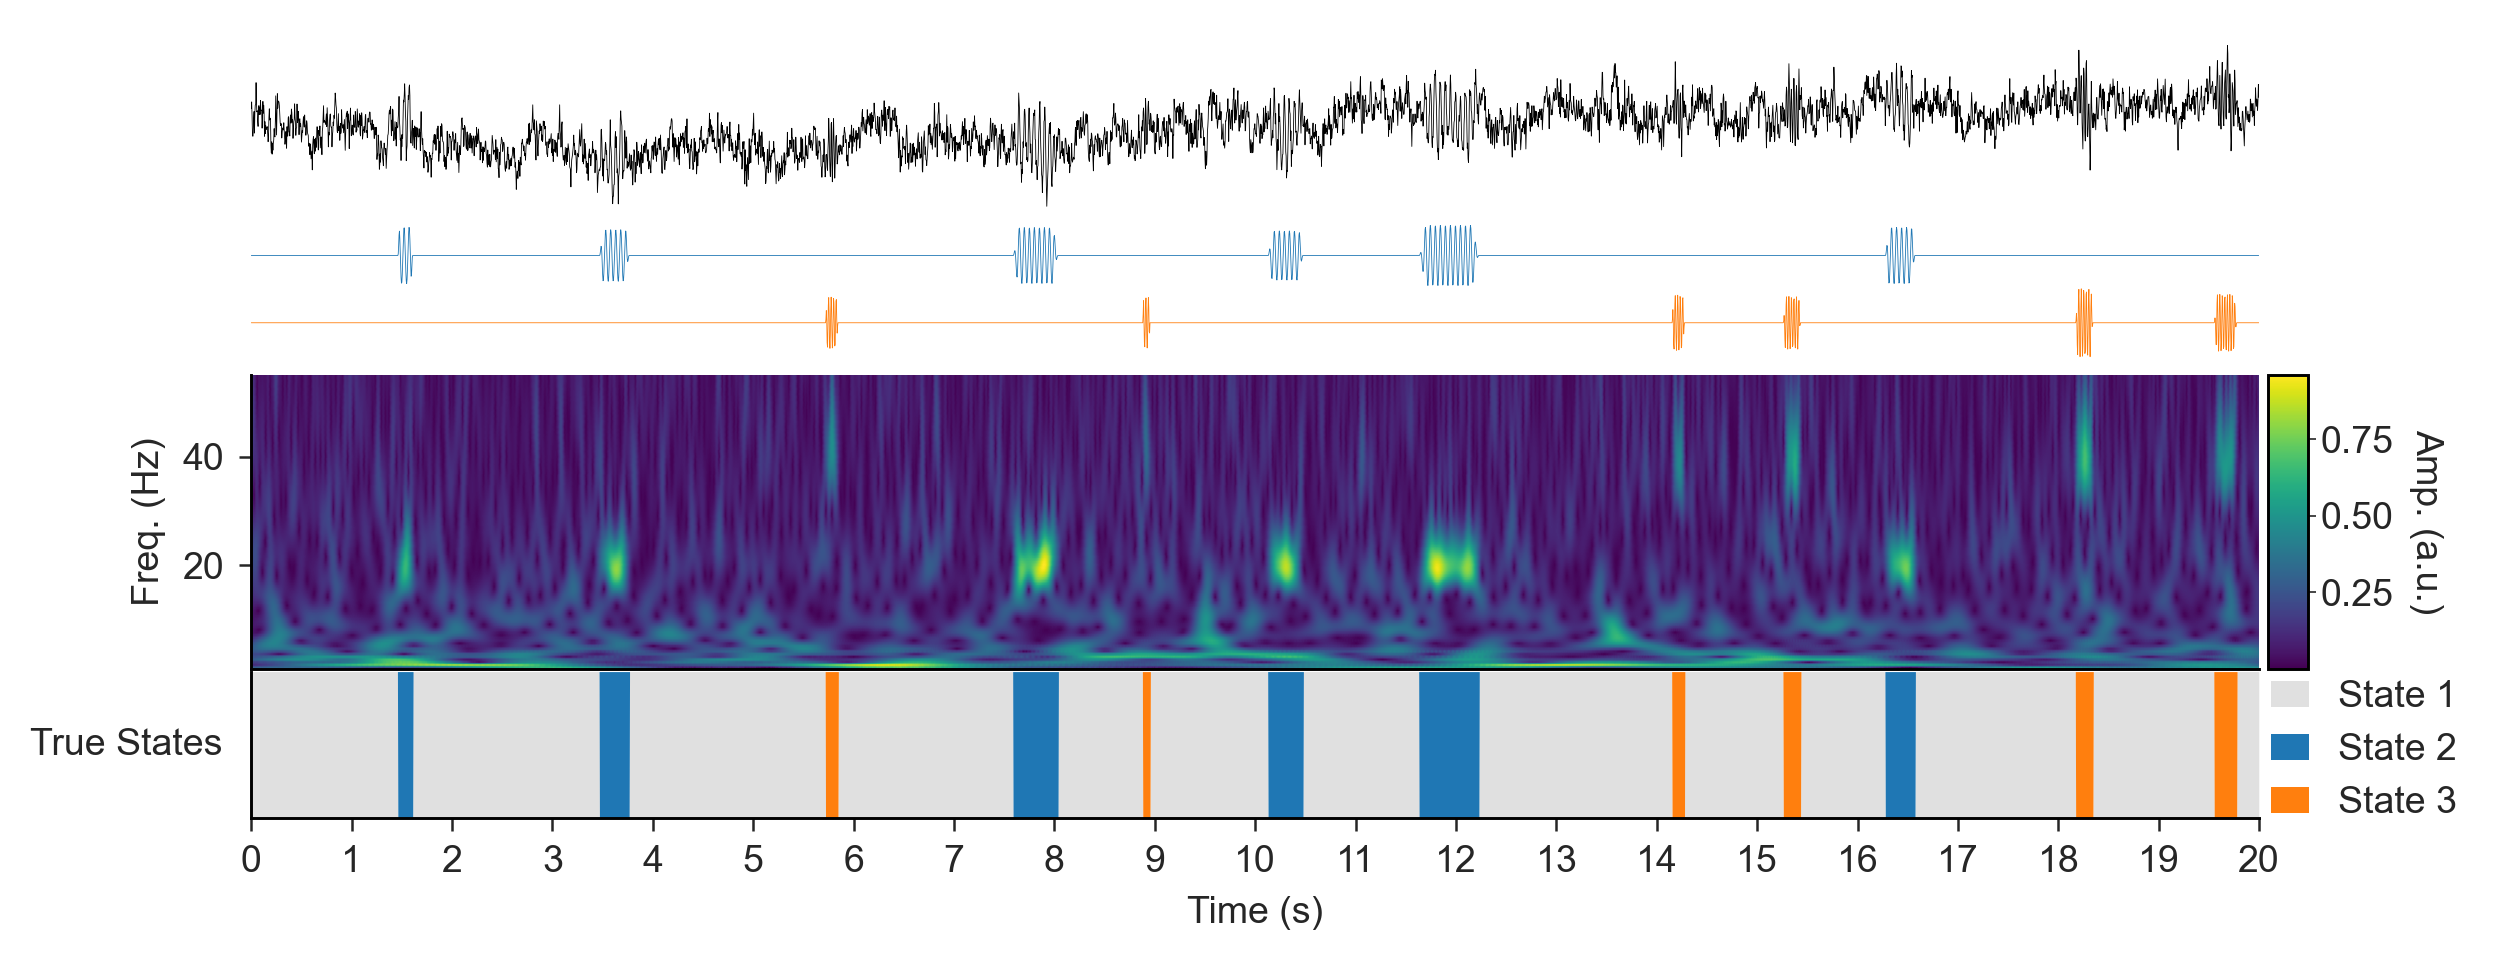

In [9]:



import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from nds_toolbox.preprocessing.features import compute_wavelet

plot_t = 20


#compute wavelet
t, f, amp = compute_wavelet(signal[:plot_t * fs], fs, f_min=1, f_max=80, df=0.5, wavelet="cmor1.5-1.0")

cmap = plt.get_cmap("tab10")
colors = [cmap(i) for i in range(true_num_states)]
grey = ["#E0E0E0"]
colors = grey + colors
state_labels = [f"State {i + 1}" for i in range(true_num_states)]

mosaic = [["b1", "b1"],
          ["b2", "b2"],
          ["b3", "b3"],
          ]

fig, axes = plt.subplot_mosaic(
    mosaic,
    figsize=(FIG_WIDTH, 3),  # a hair taller
    constrained_layout=True,
    gridspec_kw={"height_ratios": [0.7, 0.6, 0.3]}
)
fig.set_constrained_layout_pads(w_pad=0., h_pad=0., hspace=0.01)

axes["b1"].plot(time_vec[:plot_t * fs], 0.3 * (signal[:plot_t * fs]), lw=0.2, color="k")
axes["b1"].grid(False)
axes["b1"].set_frame_on(False)

axes["b1"].plot(time_vec[:plot_t * fs], 0.3 * (-2 + bursts[:plot_t * fs] * (states[:plot_t * fs] == 1)), lw=0.2,
                color=colors[1])
axes["b1"].plot(time_vec[:plot_t * fs], 0.3 * (-3 + bursts[:plot_t * fs] * (states[:plot_t * fs] == 2)), lw=0.2,
                color=colors[2])

axes["b1"].set_yticks([])
axes["b1"].set_xticks([])

for s in ("top", "right", "bottom", "left"):
    axes["b1"].spines[s].set_visible(False)
axes["b1"].set_frame_on(False)
axes["b1"].tick_params(axis='both', which='both',
                       bottom=False, top=False, left=False, right=False,
                       labelbottom=False, labelleft=False)

im = axes["b2"].imshow(
    amp, extent=[t[0], t[-1], f[0], f[-1]],
    origin="lower", aspect="auto", cmap="viridis",
    vmin=amp.min(), vmax=amp.max()
)
axes["b2"].set_ylabel("Freq. (Hz)")
#axes["b2"].set_title("Wavelet Transform", pad = 0.3)


#axes["b2"].tick_params(axis='y', which='both', left=True, labelleft=True, l)
axes["b2"].tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False, labeltop=False)
axes["b2"].yaxis.set_major_locator(MultipleLocator(20))

axes["b2"].set_ylim(1, 55)

cax = inset_axes(
    axes["b2"],  # parent axis
    width="2%",  # width as percentage of a2
    height="100%",  # match the height
    loc="center right",  # position inside a2
    borderpad=-1.3  # negative value moves it outside slightly
)

# Add the colorbar to the inset axis
cb = fig.colorbar(im, cax=cax)
cb.set_label("Amp. (a.u.)", rotation=270, labelpad=12)
cb.ax.tick_params(which="both", length=2, width=0.4, pad=1)

axes["b3"].stackplot(time_vec[:plot_t * fs], true_states_onehot[:plot_t * fs].T, linewidth=0, colors=colors,
                     labels=state_labels)
axes["b3"].set_ylabel(f"True States", rotation=0, labelpad=30, va="center")
axes["b3"].tick_params(axis='y', which='both', left=False, labelleft=False)

for key in ["b1", "b2", "b3"]:
    axes[key].sharex(axes["b1"])

axes["b3"].set_xlabel("Time (s)")
axes["b3"].xaxis.set_major_locator(MultipleLocator(1.0))
#axes["b6"].tick_params(axis='x', which='both', bottom=True, labelbottom=True, length = 0)
axes["b3"].tick_params(axis='y', which='both', left=False, labelleft=False)
axes["b3"].set_ylim(0, 1)
axes["b3"].set_xlim(0, plot_t)

axes["b3"].spines["bottom"].set_visible(True)  # keep x-axis frame

handles, labels = axes["b3"].get_legend_handles_labels()

fig.legend(handles, labels,
           loc="center left",  # anchor to left of the bbox
           ncol=1,
           bbox_to_anchor=(0.981, 0.2),  # (x, y) in figure coordinates
           frameon=False,
           handlelength=1)

plt.show()

# Time delay embedding (TDE)

In [10]:
#step1: standarize the signal before TDE
signal = (signal - np.mean(signal))/ np.std(signal)


#step2: TDE
#number of embeddings is chosen based on 2.5 cycles of the target frequency
#Here we have multiple candidate frequencies, so we use mean frequency as our target

num_emb = choose_embedding_dim(np.mean(freq), fs, min_cycles = 2.5, ensure_odd = True, verbose=True)
#you can also set it to some reasonable embeddings, say num_emb = 15

tde_signal = compute_tde(signal, num_emb)



#after TDE, num_emb//2 data points are lost from both ends of the signal
#so here we trim our signal and true state for later
trimmed_signal = trim_data(signal, num_emb, verbose = False)
trimmed_states = trim_data(states, num_emb, verbose = False)
trimmed_time_vec = np.linspace(0, len(trimmed_states)/fs, len(trimmed_states))


Chosen window size = 0.083 (sec): minimum cycles of 2.5 at 30.0 Hz
Chosen embedding dimension = 21: sampling rate = 250 Hz
10 data points were lost from both ends.
data shape: (44980, 21)


In [12]:
#roughly speaking, the expected number of states is "ln n"
num_states = int(np.ceil(np.log(len(trimmed_signal)))) # E[K] = alpha ln n
# this sets K above the expected occupied clusters

#num_states = 3 (if you wanna test with the ground truth)

num_models = 1 #default: 10
num_epochs = 3000 #default: 3000
n_jobs = 1 #increase the number of jobs when you want to multi process the inference


In [13]:

from nds_toolbox.models.dpgmm_numpyro import fit_DPGMM, truncate, get_states


In [14]:
dpgmm_result = fit_DPGMM(data=tde_signal,
                             num_states=num_states,
                             use_epoch_tqdm=False,
                             n_jobs=n_jobs,
                             use_model_tqdm=True,
                             num_models=num_models,
                             main_seed=seed,
                         num_epochs = num_epochs,
                             verbose=True)

#took about 1 min

Fitting 1 DPGMM models:   0%|          | 0/1 [00:00<?, ?model/s]


100%|██████████| 3000/3000 [00:49<00:00, 60.77it/s, init loss: 1.4446, avg. loss [2851-3000]: 0.7908]


Best negative ELBO: 0.790856
Best model ID: 0


In [35]:
params = {"data":tde_signal,
    "num_states": num_states,
    "use_epoch_tqdm":False,
    "n_jobs": n_jobs,
    "use_model_tqdm":False,
    "num_models": num_models,
    "main_seed":seed,
    "num_epochs": num_epochs,
    "verbose":False,}

In [36]:
%timeit fit_DPGMM(**params)

43.6 s ± 663 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [39]:
from nds_toolbox.models.hmm_pyro import fit_HMM

params_hmm = {"data":tde_signal,
    "num_states": num_states,
    "use_epoch_tqdm":False,
    "n_jobs": n_jobs,
    "use_model_tqdm":False,
    "num_models": num_models,
    "seed":seed,
    "num_epochs": num_epochs,
    "verbose":False,}


%timeit fit_HMM(**params_hmm)

3min 46s ± 1.6 s per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [15]:
dpgmm_result.keys()

dict_keys(['est_params', 'loss_best', 'model_id_best', 'seed_best', 'loss_all'])

In [16]:
est_params = dpgmm_result["est_params"]
loss_best = dpgmm_result["loss_best"]
loss_all = dpgmm_result["loss_all"]


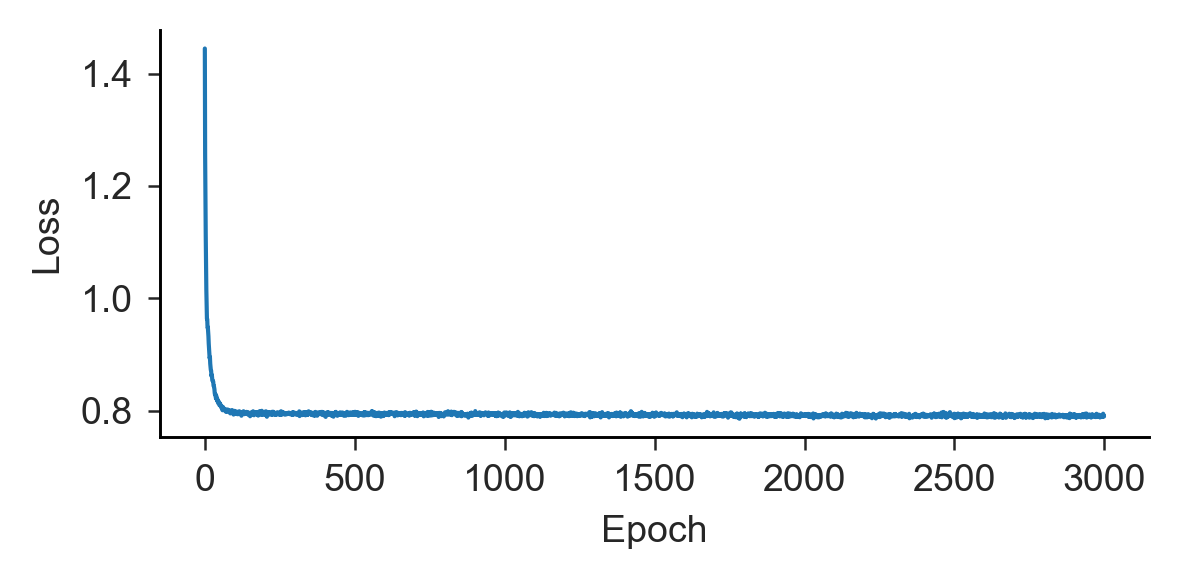

In [17]:
fig, ax = plt.subplots(figsize=(4, 2))
ax.plot(np.array(loss_all).T)
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
plt.show()

In [18]:
from nds_toolbox.utils.helper import match_states
from sklearn.metrics import matthews_corrcoef


est_params = dpgmm_result["est_params"]
alpha = est_params["alpha"]
weights = est_params["weights"]
means = est_params["means"]
covs = est_params["covs"]

#truncate tiny mixture weights and renormalize the weights
trunc_means, trunc_covs, trunc_weights, trunc_info = truncate(means, covs, weights, verbose=True, return_info=True)


#effeci
num_effective_states = len(trunc_weights)


#get the estimated states based on the learned parameters
est_states_dpgmm = get_states(tde_signal, trunc_means, trunc_covs, trunc_weights)

#one hot vector of estimated states
est_states_dpgmm_onehot = np.eye(num_effective_states)[est_states_dpgmm]


#one hot vector of true states
trimmed_states_onehot = np.eye(num_effective_states)[trimmed_states]



#order the estimated states
order, est_states_dpgmm_onehot = match_states(trimmed_states_onehot, est_states_dpgmm_onehot, verbose=False)
#onehot vector -> a signal array
est_states_dpgmm = np.argmax(est_states_dpgmm_onehot, axis=1)




[truncate]
  total components              : 11
  mass threshold                : 0.990

  Stage 1: mass truncation
    kept components             : 4
    kept original indices       : [1, 2, 8, 10]
    retained weight mass        : 0.9995
    dropped weight mass         : 0.0005

  Stage 2: edge-state removal
    CV threshold                : 0.100
    removed components          : 0
    removed original indices    : []
    CVs in active set           : [0.0231, 0.0749, 0.0298, 0.0264]

  Final result
    final components kept       : 4
    final original indices      : [1, 2, 8, 10]
    final retained weight mass  : 0.9995
    final dropped weight mass   : 0.0005


In [19]:

mcc_dpgmm = matthews_corrcoef(trimmed_states, est_states_dpgmm)
print()
print("mcc" ,mcc_dpgmm)



mcc 0.8545521505371463


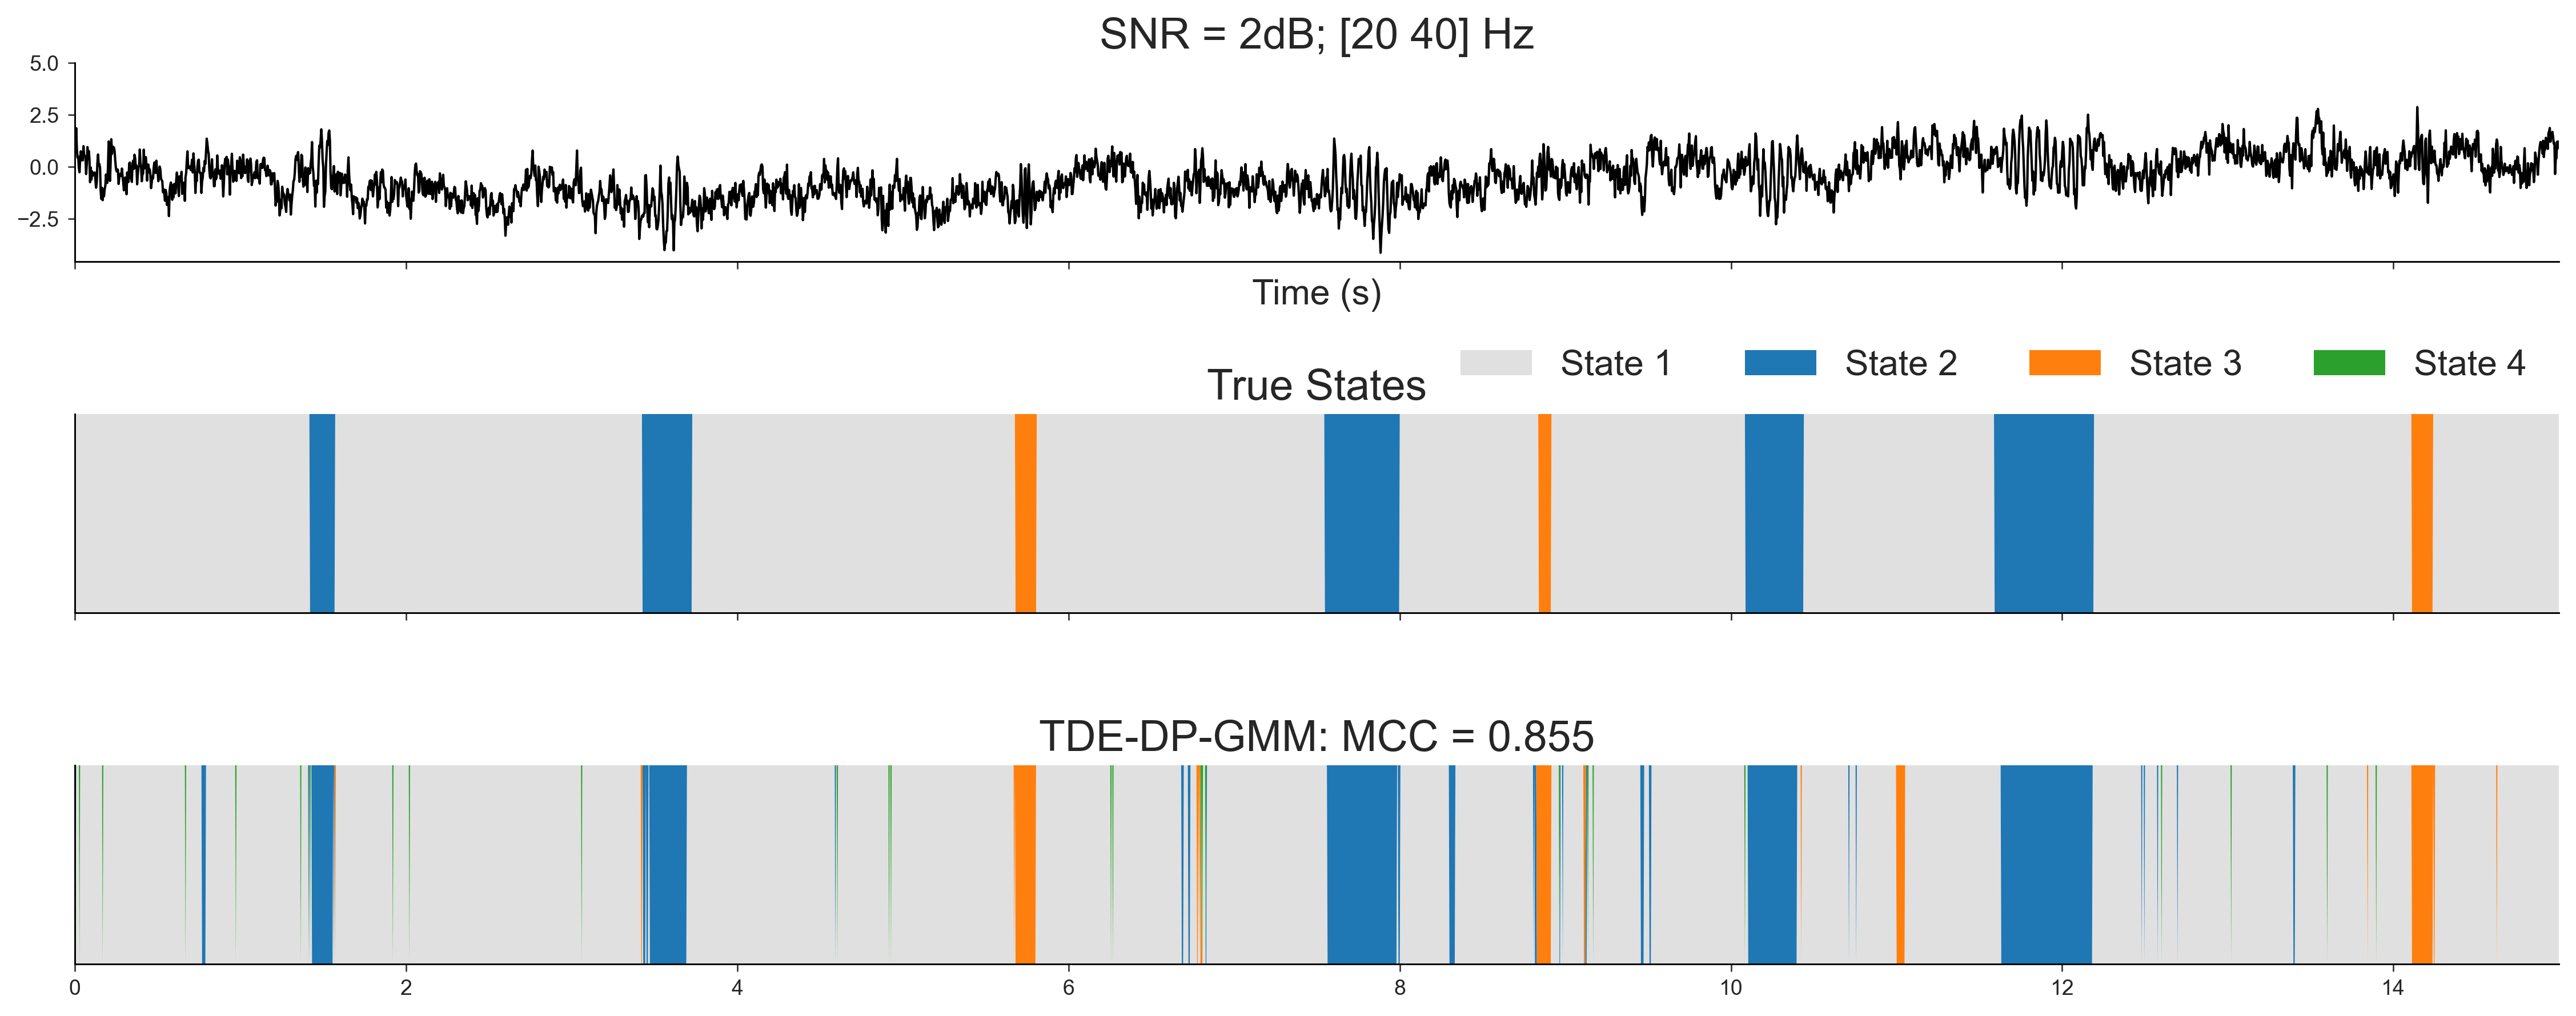

In [20]:

cmap = plt.get_cmap("tab10")
colors = [cmap(i) for i in range(num_states)]
grey = ["#E0E0E0"]
colors = grey + colors
state_labels = [f"State {i+1}" for i in range(num_states)]

fig, ax = plt.subplots(3, 1, figsize = (15, 6), sharex = True)

ax[0].plot(trimmed_time_vec, trimmed_signal, color = "k")
ax[0].set_xlabel("Time (s)", fontsize = 15)
ax[0].set_title(f"SNR = {snr_db}dB; {freq} Hz", fontsize = 18)
ax[0].set_xlim(0, 15)


ax[1].stackplot(trimmed_time_vec, trimmed_states_onehot.T, colors = colors, labels = state_labels, linewidth = 0)
ax[1].set_title("True States", fontsize = 18)
ax[1].set_ylim(0, 1)
ax[1].set_yticks([])



ax[2].stackplot(trimmed_time_vec, est_states_dpgmm_onehot.T, colors = colors, linewidth = 0)
ax[2].set_title(f"TDE-DP-GMM: MCC = {np.round(mcc_dpgmm, 3)}", fontsize = 18)
ax[2].set_ylim(0, 1)
ax[2].set_yticks([])


ax[1].legend(
    loc="lower right",
    bbox_to_anchor=(1.0, 1.0),
    ncol=num_states,
    frameon=False,
    fontsize=15,
)



plt.tight_layout()
plt.show()



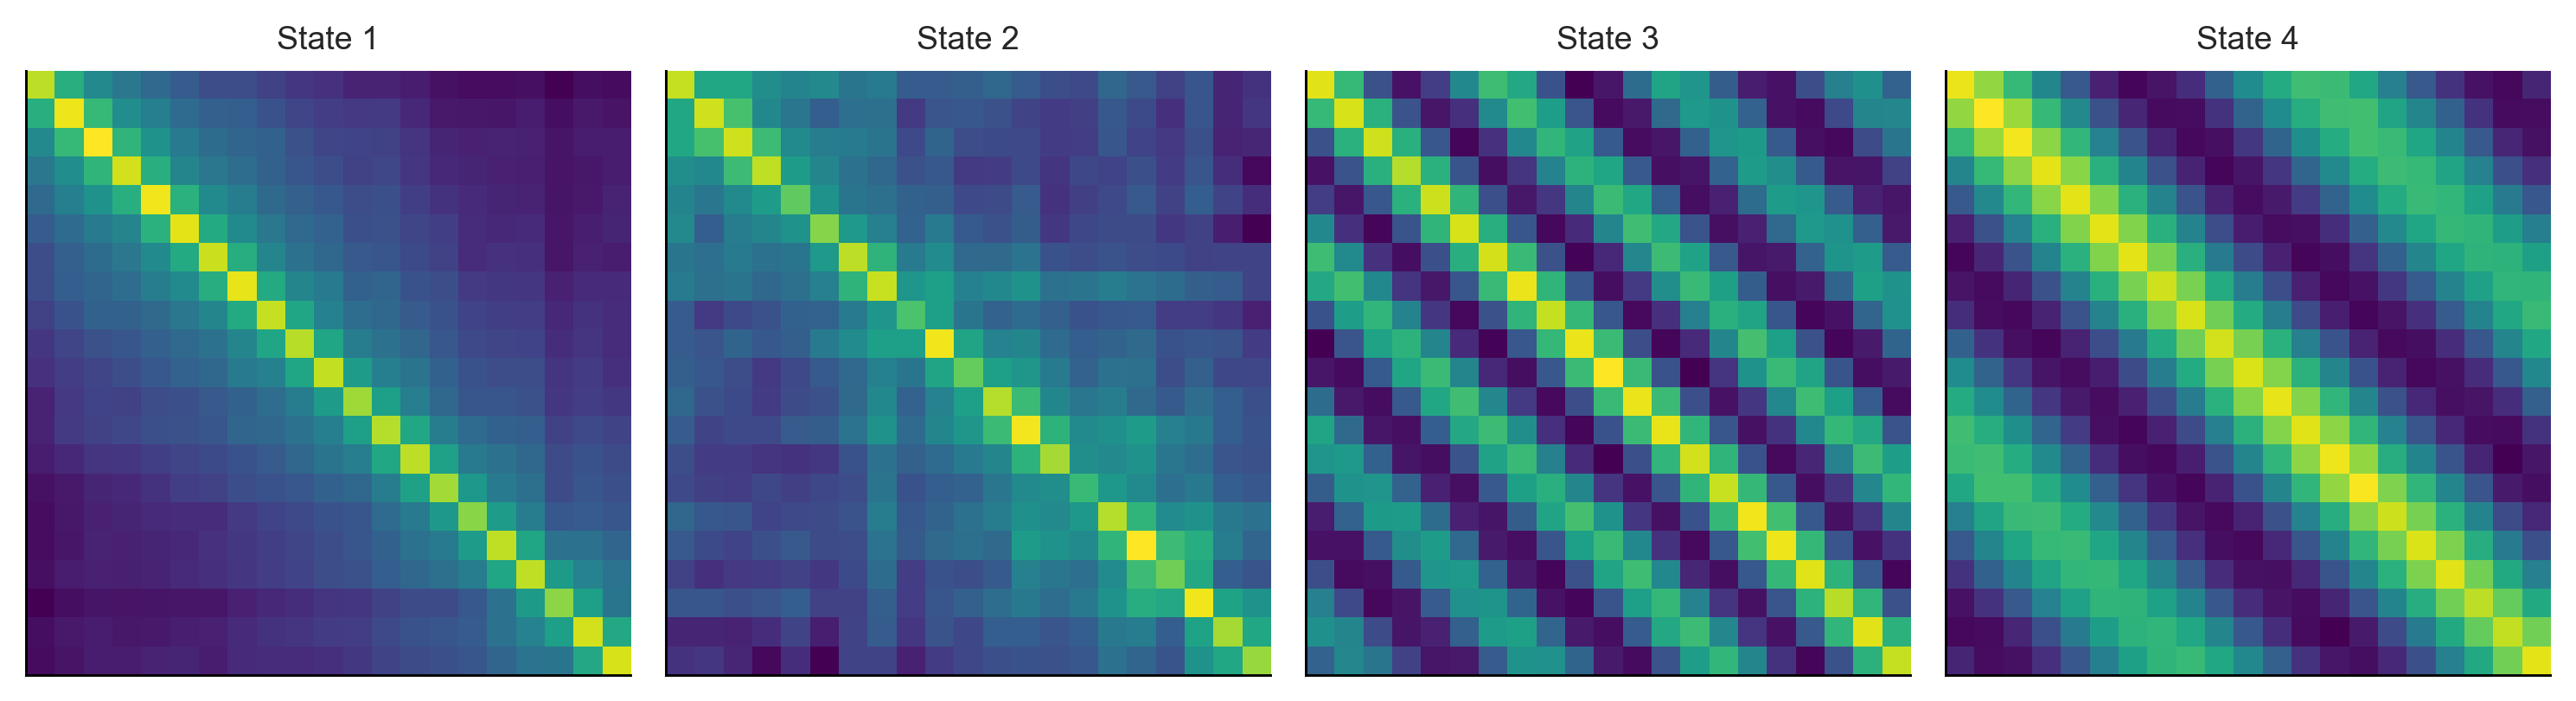

In [22]:


fig, ax = plt.subplots(1, trunc_covs.shape[0], figsize=(10, 6), sharex=True, sharey=True)

for i, cov in enumerate(trunc_covs):
    ax[i].imshow(cov, cmap="viridis")
    ax[i].set_title(f"State {i+1}")
    ax[i].set_xticks([])
    ax[i].set_yticks([])

plt.show()


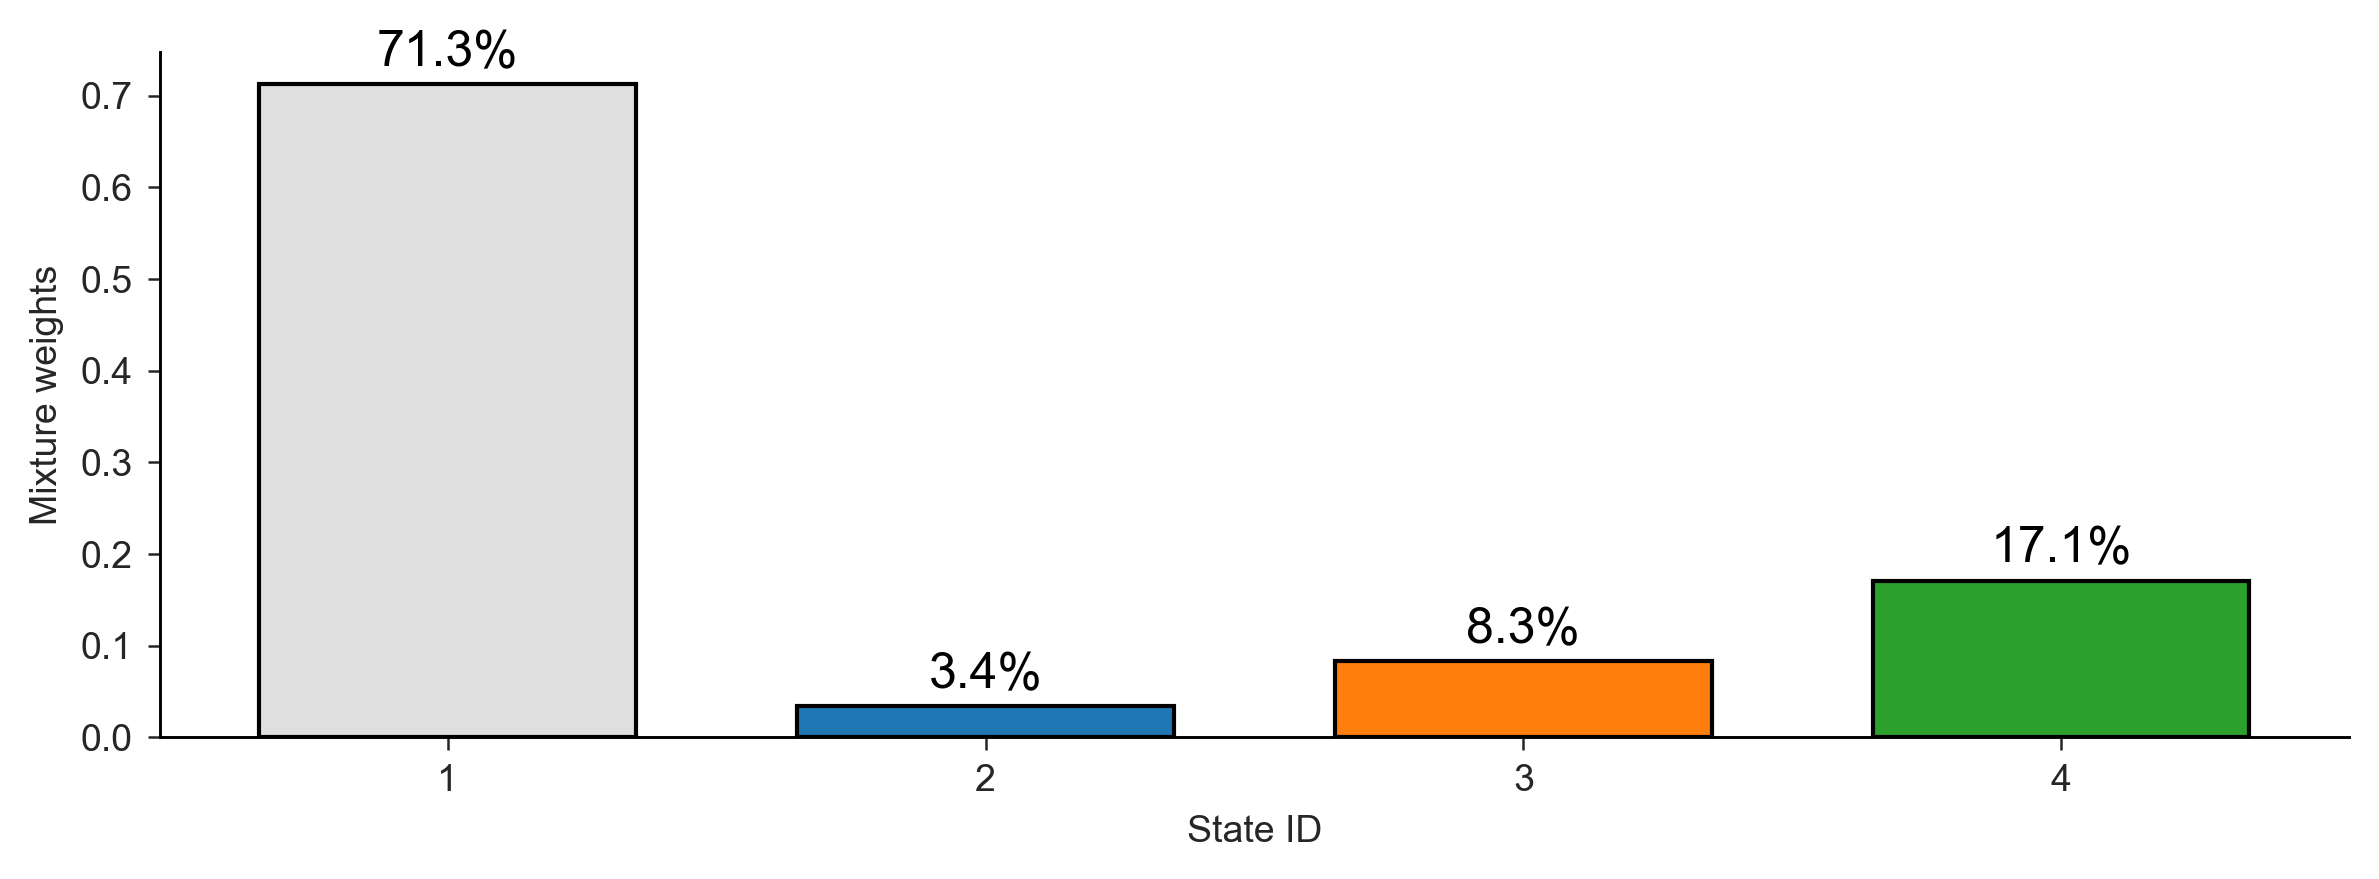

In [23]:

fig, ax = plt.subplots(1, 1, figsize=(8, 3))

for k, w in enumerate(trunc_weights):
        ax.bar(
            k,
            w,
            width=0.7,
            color=colors[k],
            zorder=1,
            align="center",
            edgecolor="k",
        )
        ax.text(
            k,
            w + 0.02,
            f"{w * 100:.1f}%",
            ha="center",
            color="k",
            fontsize=12,
        )

ax.set_ylabel("Mixture weights")
ax.set_xlabel("State ID")
ax.set_xticks(np.arange(num_effective_states), labels=np.arange(1, num_effective_states + 1))
plt.show()